# 3. Uplift modelling: who should get the discount?

Notebook 01 ended with a problem: the average effect of the 20% discount is about zero, but it's negative for users in rich countries (T1) and probably positive for price-sensitive ones (T3). Hunting for segments by slicing the data in many ways is p-hacking, so here I try to do it properly with heterogeneous treatment effect estimation.

The goal is to estimate the conditional average treatment effect $\tau(x)=E[Y(1)-Y(0)\mid X=x]$ from the randomized data and use it to decide who gets the new price.

How:
1. Four learners, all using only pre-experiment features.
2. Cross-fitting: every user is scored by a model that never saw them, so the whole 200k sample can be used for evaluation.
3. Two kinds of evaluation: what a real analyst could compute (Qini curves, inverse propensity policy value on the RCT) and the simulator's ground truth.

> All data is simulated. The model hyperparameters were fixed up front and were not tuned on the ground truth.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.tree import DecisionTreeRegressor, export_text
from IPython.display import display

from src.simulator import simulate, SimConfig
from src import analysis as an, uplift as up

from src.plotting import use_style, SURFACE, INK, INK2, MUTED, GRID, AXIS, BLUE, ORANGE
use_style()
pd.options.display.float_format = "{:,.4f}".format

cfg = SimConfig()
df = simulate(cfg)                                            # same 200k-user experiment as notebooks 01-02
X = up.make_features(df)                                      # pre-experiment covariates only
t, y, conv = df.treatment.to_numpy(), df.revenue_30d.to_numpy(), df.converted.to_numpy()
price = np.where(t == 1, cfg.price_variant, cfg.price_control)
true_cate, ite = df.true_cate_revenue_30d.to_numpy(), df.true_ite_revenue_30d.to_numpy()
print("Features:", up.FEATURES)

Features: ['sessions_pre', 'tenure_days', 'revenue_pre_30d', 'is_ios', 'tier_T1', 'tier_T2', 'tier_T3']


## 1. The four learners

| Learner | Idea | Weakness |
|---|---|---|
| S | one model $\hat\mu(x,T)$; $\hat\tau=\hat\mu(x,1)-\hat\mu(x,0)$ | the treatment is one weak feature among many, so a regularized model shrinks its effect to zero |
| T | one model per arm; $\hat\tau=\hat\mu_1(x)-\hat\mu_0(x)$ | each model has its own noise, and the noise of the difference is much larger than the effect |
| DR (doubly robust) | pseudo-outcome $\psi=\hat\mu_1-\hat\mu_0+\frac{T(Y-\hat\mu_1)}{e}-\frac{(1-T)(Y-\hat\mu_0)}{1-e}$, then regress $\psi$ on $x$ | unbiased for any $\hat\mu$ (the propensity $e=0.5$ is known), but $\psi$ is very noisy |
| Structural | model the conversion CATE (0/1 outcome, low noise) and turn it into revenue with the price algebra | depends on two assumptions (below) |

The idea behind the structural learner: revenue is $\text{price}_{\text{arm}}\times\text{converted}+\text{IAP}$ (IAP = in-app purchases), so
$$\tau_{\text{rev}}(x)=p_v\,\tau_{\text{conv}}(x)+(p_v-p_c)\,\hat q_c(x),$$
where $p_c=9.99$ and $p_v=7.99$ are the known prices and $\hat q_c(x)$ is the baseline conversion probability. The heavy-tailed IAP noise never enters the model. More generally: model the part of the metric the treatment can actually move, with the least noisy outcome available, and add the known structure back with algebra.

The two assumptions are that the prices are known and that in-app purchases don't react to the price. The second one can be tested on the aggregate:

In [2]:
iap = y - price * conv                                       # revenue that is not the subscription
print("Effect of the discount on in-app purchases:", an.diff_in_means(iap, t))

Effect of the discount on in-app purchases: +0.0052  95% CI [-0.0346, +0.0450]  se=0.0203  p=0.798


No detectable effect on in-app purchases (the interval is centred on zero), so the assumption is consistent with the data. A null result can't prove it, of course; in a real product I'd also want a reason why the price shouldn't affect in-app spending.

## 2. Fitting with 5-fold cross-fitting

In [3]:
learners = {
    "S": (up.s_learner, {}),
    "T": (up.t_learner, {}),
    "DR": (up.dr_learner, {}),
    "Structural": (up.structural_learner, {"conv": conv, "price_control": cfg.price_control, "price_variant": cfg.price_variant}),
}
tau = {name: up.cross_fit(fn, X, t, y, n_folds=5, seed=0, **kw) for name, (fn, kw) in learners.items()}
print({k: v.shape for k, v in tau.items()})

{'S': (200000,), 'T': (200000,), 'DR': (200000,), 'Structural': (200000,)}


## 3. How accurate are the CATE estimates?

This part only works in a simulation: compare $\hat\tau(x)$ with the true expected effect. The benchmark is a constant predictor that always says "the effect is the average". A learner that does worse than that is adding noise.

In [4]:
ate = ite.mean()
rows = [{"method": "Constant (always the ATE)", "RMSE vs true CATE": np.sqrt(np.mean((true_cate - true_cate.mean()) ** 2)),
         "Spearman vs true CATE": np.nan, "share with tau>0": np.nan}]
for name, v in tau.items():
    rows.append({"method": name, "RMSE vs true CATE": np.sqrt(np.mean((v - true_cate) ** 2)),
                 "Spearman vs true CATE": spearmanr(v, true_cate)[0], "share with tau>0": np.mean(v > 0)})
acc = pd.DataFrame(rows).set_index("method"); display(acc)
print(f"True: share of users with CATE>0 = {np.mean(true_cate > 0):.2f}")

by_tier = pd.DataFrame({name: pd.Series(v).groupby(df.tier.to_numpy()).mean() for name, v in tau.items()})
by_tier["TRUE"] = pd.Series(true_cate).groupby(df.tier.to_numpy()).mean()
print("\nMean estimated effect by tier (EUR / user):"); display(by_tier)

,RMSE vs true CATE,Spearman vs true CATE,share with tau>0
method,,,
Constant (always the ATE),0.0744,NaN,NaN
S,0.0933,0.5228,0.1475
T,0.3631,0.6623,0.5952
DR,0.0783,0.4978,0.5468
Structural,0.0489,0.8120,0.5381


True: share of users with CATE>0 = 0.42

Mean estimated effect by tier (EUR / user):


,S,T,DR,Structural,TRUE
T1,-0.0024,-0.1202,-0.0396,-0.0817,-0.0825
T2,-0.0029,0.0153,0.0053,0.0079,-0.0123
T3,0.0048,0.0833,0.0072,0.0382,0.0761


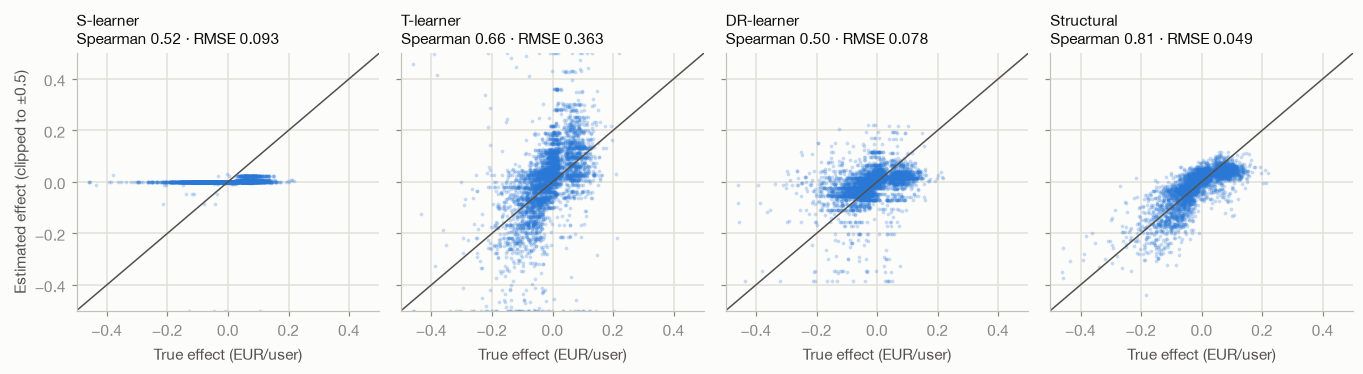

In [5]:
labels = {"S": "S-learner", "T": "T-learner", "DR": "DR-learner", "Structural": "Structural"}
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.5), sharex=True, sharey=True)
rs = np.random.default_rng(0).choice(len(df), 4000, replace=False)
lim = 0.5
for ax, name in zip(axes, labels):
    ax.scatter(true_cate[rs], np.clip(tau[name][rs], -lim, lim), s=6, color=BLUE, alpha=0.25, linewidths=0)
    ax.plot([-lim, lim], [-lim, lim], color=INK2, lw=1)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_title(f"{labels[name]}\nSpearman {acc.loc[name, 'Spearman vs true CATE']:.2f} · RMSE {acc.loc[name, 'RMSE vs true CATE']:.3f}",
                 loc="left", fontsize=10, color=INK)
    ax.set_xlabel("True effect (EUR/user)")
axes[0].set_ylabel("Estimated effect (clipped to ±0.5)")
fig.tight_layout(); fig.savefig("../reports/figures/03_cate_accuracy.png", dpi=160); plt.show()

- S-learner: everything is shrunk toward zero. It labels only ~15% of users as positive when ~40% really are, and its RMSE is worse than the constant.
- T-learner: the ranking is decent (Spearman ~0.66) but the magnitudes are absurd, with an error about 5x the constant predictor's. Ranking and calibration are two different things, and "treat if $\hat\tau>0$" needs both.
- DR-learner: unbiased in theory, but the pseudo-outcome is so noisy that a regularized final model barely keeps any signal. No better than the constant.
- Structural: the only one that clearly beats the constant (RMSE ~0.049 vs 0.074), and it ranks users well (Spearman ~0.81).

The tier averages show what each learner "believes". S and DR flatten T1 and T3 toward zero and miss the -0.08 / +0.08 gap found in notebook 01. The T-learner overshoots on average (-0.12 / +0.08) and its individual scores are very noisy. The structural learner gets T1 almost exactly (-0.082 vs -0.083) and T3 about half way (+0.038 vs +0.076). It also has a small positive bias in T2 (+0.008 vs -0.012), which is why it treats 54% of users while the oracle treats 42%.

## 4. Ranking quality: gain curves (Qini)

Sort users by $\hat\tau$ from highest to lowest and give the discount only to the top share $q$. The curve shows the extra revenue per user of the whole population as $q$ grows. A good model rises above the straight line of random targeting, peaks, and comes back down to the ATE when everyone is treated (treating users with a negative effect loses money). The observed version uses only the experiment data (difference in means inside the top-$q$ group); the truth version averages the true individual effects. AUUC is the area between the curve and the random line.

In [6]:
curves_obs, curves_true, rows = {}, {}, []
for name, v in {**tau, "Oracle (true CATE)": true_cate}.items():
    qo, co = up.gain_curve(v, t=t, y=y); qt, ct = up.gain_curve(v, ite=ite)
    curves_obs[name], curves_true[name] = (qo, co), (qt, ct)
    rows.append({"method": name, "AUUC (observed data)": up.auuc(qo, co, ate), "AUUC (ground truth)": up.auuc(qt, ct, ate)})
display(pd.DataFrame(rows).set_index("method"))

,AUUC (observed data),AUUC (ground truth)
method,,
S,0.0120,0.0069
T,0.0112,0.0143
DR,0.0061,0.0097
Structural,0.0200,0.0174
Oracle (true CATE),0.0239,0.0211


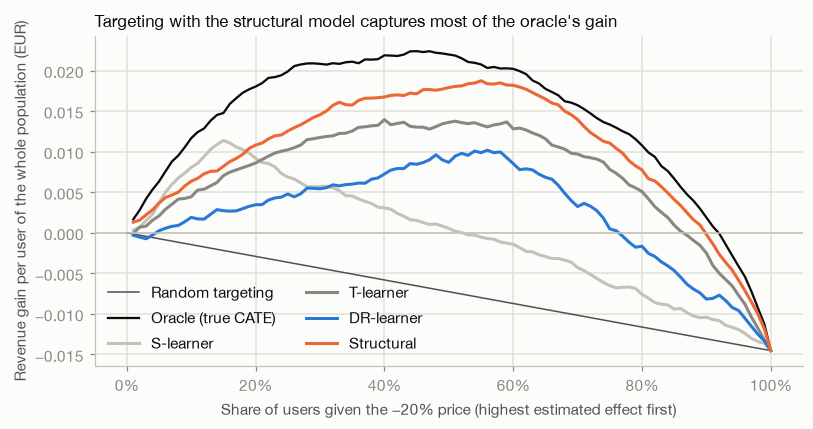

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.0))
style = {"S": (AXIS, "S-learner"), "T": (MUTED, "T-learner"), "DR": (BLUE, "DR-learner"), "Structural": (ORANGE, "Structural")}
ax.plot([0, 1], [0, ate], color=INK2, lw=1, label="Random targeting")
q, c = curves_true["Oracle (true CATE)"]; ax.plot(q, c, color=INK, lw=1.5, label="Oracle (true CATE)")
for name, (color, lab) in style.items():
    q, c = curves_true[name]; ax.plot(q, c, color=color, lw=2, label=lab)
ax.axhline(0, color=AXIS, lw=1)
ax.set_xlabel("Share of users given the −20% price (highest estimated effect first)")
ax.set_ylabel("Revenue gain per user of the whole population (EUR)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Targeting with the structural model captures most of the oracle's gain", loc="left", fontsize=11, color=INK)
ax.legend(loc="lower left", ncol=2)
fig.tight_layout(); fig.savefig("../reports/figures/03_gain_curves.png", dpi=160); plt.show()

The structural learner's curve stays close to the oracle's, and S, T and DR sit between random targeting and the oracle. The observed AUUC, which is what you'd have without the truth, does pick the structural learner as the clear winner, but it ranks the other three differently from the ground truth. Qini curves on revenue are noisy, so I wouldn't read much into small differences between mediocre models.

## 5. Who gets the new price?

A policy here is "give the discount to users with $\hat\tau>0$", and its value is $E[\pi(x)\,\tau(x)]$. On RCT data it can be estimated without modelling assumptions by inverse propensity weighting:
$\hat V(\pi)=\frac1N\sum_i \pi(x_i)\left[\frac{T_iY_i}{e}-\frac{(1-T_i)Y_i}{1-e}\right]$.
Since the scores are cross-fitted, this estimate doesn't have the winner's curse problem from notebook 01.

Its weakness is variance, because the heavy-tailed in-app revenue swamps everything. If in-app purchases don't react to the price (checked above), I can estimate the same policy value on subscription revenue only, which is much less noisy.

In [8]:
y_sub = price * conv                                          # subscription revenue only
policies = {"Ship to everyone": np.ones(len(df)),
            "Tier rule: T3 only (notebook 01)": (df.tier == "T3").to_numpy().astype(float),
            "S-learner": (tau["S"] > 0).astype(float), "T-learner": (tau["T"] > 0).astype(float),
            "DR-learner": (tau["DR"] > 0).astype(float), "Structural": (tau["Structural"] > 0).astype(float),
            "Oracle (true CATE > 0)": (true_cate > 0).astype(float)}
rows = []
for name, pol in policies.items():
    g, se = up.policy_gain(y, t, pol); gs, ses = up.policy_gain(y_sub, t, pol)
    rows.append({"policy": name, "% users treated": pol.mean(),
                 "est. gain, total revenue": g, "± 95%": 1.96 * se,
                 "est. gain, subscription only": gs, "± 95% (sub)": 1.96 * ses,
                 "TRUE gain 30d": np.mean(pol * ite), "TRUE gain 60d": np.mean(pol * df.true_ite_revenue_60d.to_numpy())})
pol_tab = pd.DataFrame(rows).set_index("policy")
display(pol_tab.style.format({"% users treated": "{:.0%}", **{c: "{:+.4f}" for c in pol_tab.columns if c != "% users treated"}}))
print("TRUE gain 30d in EUR per 1M users:", (pol_tab["TRUE gain 30d"] * 1e6).round(0).astype(int).to_dict())

,% users treated,"est. gain, total revenue",± 95%,"est. gain, subscription only",± 95% (sub),TRUE gain 30d,TRUE gain 60d
policy,,,,,,,
Ship to everyone,100%,-0.0110,+0.0448,-0.0167,+0.0181,-0.0145,-0.0384
Tier rule: T3 only (notebook 01),25%,+0.0134,+0.0229,+0.0165,+0.0078,+0.0198,+0.0252
S-learner,15%,+0.0131,+0.0121,+0.0089,+0.0059,+0.0114,+0.0146
T-learner,60%,+0.0120,+0.0259,+0.0140,+0.0125,+0.0131,+0.0109
DR-learner,55%,+0.0094,+0.0295,+0.0085,+0.0124,+0.0099,+0.0051
Structural,54%,+0.0264,+0.0253,+0.0184,+0.0116,+0.0186,+0.0208
Oracle (true CATE > 0),42%,+0.0201,+0.0246,+0.0174,+0.0098,+0.0218,+0.0267


TRUE gain 30d in EUR per 1M users: {'Ship to everyone': -14522, 'Tier rule: T3 only (notebook 01)': 19755, 'S-learner': 11394, 'T-learner': 13129, 'DR-learner': 9863, 'Structural': 18570, 'Oracle (true CATE > 0)': 21820}


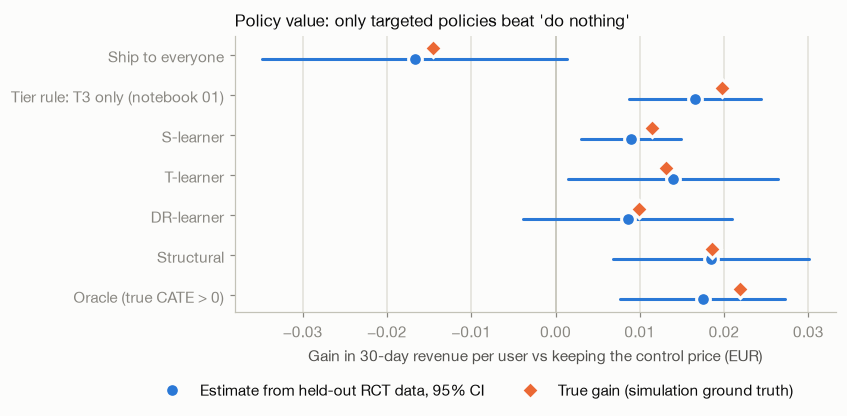

In [9]:
fig, ax = plt.subplots(figsize=(7.8, 4.0))
rowsp = pol_tab.iloc[::-1]                                     # first policy at the top
ypos = np.arange(len(rowsp))
ax.axvline(0, color=AXIS, lw=1)
for yp, (_, r) in zip(ypos, rowsp.iterrows()):
    ax.plot([r["est. gain, subscription only"] - r["± 95% (sub)"], r["est. gain, subscription only"] + r["± 95% (sub)"]],
            [yp - 0.1] * 2, color=BLUE, lw=2, solid_capstyle="round")
ax.plot(rowsp["est. gain, subscription only"], ypos - 0.1, "o", color=BLUE, ms=9, mec=SURFACE, mew=2, label="Estimate from held-out RCT data, 95% CI")
ax.plot(rowsp["TRUE gain 30d"], ypos + 0.17, "D", color=ORANGE, ms=8, mec=SURFACE, mew=2, label="True gain (simulation ground truth)")
ax.set_yticks(ypos, rowsp.index); ax.grid(axis="y", visible=False)
ax.set_xlabel("Gain in 30-day revenue per user vs keeping the control price (EUR)")
ax.set_title("Policy value: only targeted policies beat 'do nothing'", loc="left", fontsize=11, color=INK)
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.2), ncol=2)
fig.tight_layout(); fig.savefig("../reports/figures/03_policy_value.png", dpi=160, bbox_inches="tight"); plt.show()

- Shipping to everyone loses money, as in notebook 01. Targeting with the structural model earns about +0.019 € per user (~19k € per million users in 30 days), roughly 85% of what the oracle gets, and with the subscription-only estimate its confidence interval excludes zero. The total-revenue estimate in the table is too noisy for that: its interval is more than twice as wide.
- The S, T and DR policies earn less in truth (~0.010-0.013 € per user). The S-learner policy is safe but small (it treats 15% of users), and the interval of the DR policy's estimated gain includes zero.
- The simple tier rule from notebook 01 (T3 only) does about as well as the structural learner. In this simulation the heterogeneity mostly comes from one variable, country tier, which was already an obvious segment. A model would add more when the differences are spread over many variables and nobody planned the segments in advance.
- The policies are chosen on 30-day revenue, but the table also shows the true 60-day gain. For the best targeted policies (T3 rule, structural, oracle) it's higher than at 30 days, while for the T- and DR-learner policies it's lower (they also treat users the discount only helps in the short run). Shipping to everyone gets much worse (-0.038).

## 6. Can the scores be trusted?

Calibration: I split users into five equal bins by predicted effect and compare the average prediction in each bin with the effect measured in the experiment (difference in means on subscription revenue, with a 95% CI).

,mean predicted,observed effect,ci_low,ci_high,true mean CATE
bin,,,,,
1,-0.1335,-0.1518,-0.2013,-0.1022,-0.1044
2,-0.0329,-0.0401,-0.0799,-0.0003,-0.0459
3,0.0048,0.0366,-0.0004,0.0737,-0.0053
4,0.0280,0.0222,-0.0125,0.0570,0.0252
5,0.0543,0.0463,0.0132,0.0794,0.0568


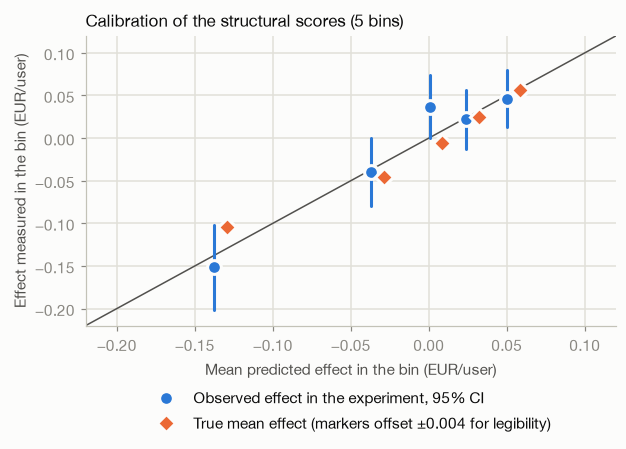

In [10]:
sc = tau["Structural"]
bins = pd.qcut(sc, 5, labels=False)
rows = []
for b in range(5):
    m = bins == b
    e = an.diff_in_means(y_sub[m], t[m])
    rows.append({"bin": b + 1, "mean predicted": sc[m].mean(), "observed effect": e.estimate, "ci_low": e.ci_low, "ci_high": e.ci_high,
                 "true mean CATE": true_cate[m].mean()})
cal = pd.DataFrame(rows).set_index("bin"); display(cal)

fig, ax = plt.subplots(figsize=(5.8, 4.3))
lo_, hi_ = -0.22, 0.12
ax.plot([lo_, hi_], [lo_, hi_], color=INK2, lw=1)
for _, r in cal.iterrows():
    ax.plot([r["mean predicted"] - 0.004] * 2, [r.ci_low, r.ci_high], color=BLUE, lw=2, solid_capstyle="round")
ax.plot(cal["mean predicted"] - 0.004, cal["observed effect"], "o", color=BLUE, ms=9, mec=SURFACE, mew=2, label="Observed effect in the experiment, 95% CI")
ax.plot(cal["mean predicted"] + 0.004, cal["true mean CATE"], "D", color=ORANGE, ms=8, mec=SURFACE, mew=2, label="True mean effect (markers offset ±0.004 for legibility)")
ax.set_xlim(lo_, hi_); ax.set_ylim(lo_, hi_)
ax.set_xlabel("Mean predicted effect in the bin (EUR/user)"); ax.set_ylabel("Effect measured in the bin (EUR/user)")
ax.set_title("Calibration of the structural scores (5 bins)", loc="left", fontsize=11, color=INK)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=1)
fig.tight_layout(); fig.savefig("../reports/figures/03_calibration.png", dpi=160, bbox_inches="tight"); plt.show()

A score from a black box is hard to act on, so I fit a depth-2 decision tree on the structural scores to turn them into a few readable rules. This describes the model; it's not a new causal estimate.

In [11]:
tree = DecisionTreeRegressor(max_depth=2, min_samples_leaf=10_000, random_state=0).fit(X, tau["Structural"])
print(export_text(tree, feature_names=up.FEATURES, decimals=3))

|--- tier_T1 <= 0.500
|   |--- sessions_pre <= 15.500
|   |   |--- value: [0.028]
|   |--- sessions_pre >  15.500
|   |   |--- value: [-0.040]
|--- tier_T1 >  0.500
|   |--- sessions_pre <= 9.500
|   |   |--- value: [-0.038]
|   |--- sessions_pre >  9.500
|   |   |--- value: [-0.162]



Predictions and measured effects line up across the five bins: every interval covers the diagonal and the order is right up to noise (bins 3 and 4 can't be told apart). The rules split first on "is the user in T1?" and then on pre-experiment sessions. The discount hurts T1 users, especially the most engaged ones (-0.16), and helps less engaged users outside T1 (+0.03). That's consistent with how I built the simulator (price sensitivity falls with engagement), but a real analyst wouldn't know it beforehand, so I'd treat it as a hypothesis for the confirmatory test.

## Summary

1. Fitting ML models directly on a noisy, heavy-tailed revenue metric works poorly for heterogeneous effects: S shrinks, T explodes, DR is unbiased but noisy. Always compare with a constant predictor.
2. Using the structure of the problem helped much more than a fancier model would have. Modelling conversion and adding the known price algebra gave better accuracy, better targeting and a policy value whose interval excludes zero.
3. The evaluation has to be honest: cross-fitting plus inverse propensity policy values on the RCT avoid the winner's curse. Qini curves on revenue are noisy.
4. A simple baseline matters. The one-variable tier rule was just as good here, so a model has to earn its complexity.
5. Before a rollout I'd confirm the targeted policy with a follow-up experiment (a holdout inside the targeted group), since an estimated policy value isn't a measured one.

Next: notebook 04 applies the same tools to the real Hillstrom e-mail experiment.